# Análise de Dados de Internamentos Hospitalares
Este notebook executa a análise exploratória e estatística carregando os dados diretamente a partir de um ficheiro CSV externo.

## 1. Importação de Bibliotecas e Leitura do Ficheiro CSV

In [33]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual style configuration for plots
sns.set_theme(style="whitegrid")

# Define file path by navigating 3 levels up from the current working directory
file_path = (Path.cwd() / "../../../tools/data-generation/output/dataset.csv").resolve()

# Check if the file exists before reading
if file_path.exists():
    df = pd.read_csv(file_path)
    print(f"File successfully loaded from: {file_path}\n")
else:
    print(f"Error: File not found at path:\n{file_path}")
    df = None

File successfully loaded from: C:\Users\RuiMiguelSoaresRodri\Desktop\Mestrado\2_Ano\PI\PatientFlow\tools\data-generation\output\dataset.csv



## 2. Processamento e Cálculo de Métricas (Idade e Tempo de Internamento)

In [34]:
if df is not None:
    # Convert date/time columns to datetime format
    df['birthdate'] = pd.to_datetime(df['birthdate'])
    df['admission date'] = pd.to_datetime(df['admission date'])
    df['discharge date'] = pd.to_datetime(df['discharge date'])

    # 1. Calculate age at admission date (in years)
    df['age'] = ((df['admission date'] - df['birthdate']).dt.days / 365.25).astype(int)

    # 2. Calculate Length of Stay (LOS) in full days
    df['los_days'] = (df['discharge date'] - df['admission date']).dt.days

    # 3. Determine season at admission date (Northern Hemisphere)
    def get_season(date):
        month = date.month
        day = date.day
        if (month == 12 and day >= 21) or month in [1, 2] or (month == 3 and day < 20):
            return 'Winter'
        elif (month == 3 and day >= 20) or month in [4, 5] or (month == 6 and day < 21):
            return 'Spring'
        elif (month == 6 and day >= 21) or month in [7, 8] or (month == 9 and day < 23):
            return 'Summer'
        else:
            return 'Autumn'

    df['season'] = df['admission date'].apply(get_season)

    # Display dataset preview with the engineered features
    display(df[['gender', 'diagnosis code', 'age', 'los_days', 'season']].head())

,gender,diagnosis code,age,los_days,season
0,M,K80.20,48,2,Autumn
1,F,R65.21,52,14,Autumn
2,M,C18.9,82,7,Autumn
3,M,C18.9,39,5,Autumn
4,M,C18.9,75,2,Autumn


## 3. Resumo Estatístico dos Dados

In [35]:
if df is not None:
    print("=== GENERAL STATISTICS ===")
    print(f"Total patients: {len(df)}")
    print(f"Average age: {df['age'].mean():.1f} years")
    print(f"Average length of stay: {df['los_days'].mean():.2f} days")

    print("\n=== GENDER DISTRIBUTION ===")
    print(df['gender'].value_counts())

    print("\n=== COUNT BY ICD-10 DIAGNOSIS CODE ===")
    print(df['diagnosis code'].value_counts())
    
    print("\n=== ADMISSIONS BY SEASON ===")
    print(df['season'].value_counts())

=== GENERAL STATISTICS ===
Total patients: 1000
Average age: 67.8 years
Average length of stay: 6.71 days

=== GENDER DISTRIBUTION ===
gender
M    512
F    488
Name: count, dtype: int64

=== COUNT BY ICD-10 DIAGNOSIS CODE ===
diagnosis code
I50.9       65
J18.9       65
K56.60      63
D64.9       54
I44.2       50
I48.91      49
K80.20      47
M17.9       47
K40.90      47
N17.9       47
C18.9       47
S82.899A    45
K35.80      44
M16.9       39
S72.009A    37
E86.0       36
N39.0       36
I61.9       33
J44.1       25
I63.9       24
I21.4       22
J96.00      22
G40.909     22
C34.90      16
G45.9       15
R65.21       2
I46.9        1
Name: count, dtype: int64

=== ADMISSIONS BY SEASON ===
season
Spring    253
Winter    252
Autumn    248
Summer    247
Name: count, dtype: int64


## 4. Visualização Gráfica

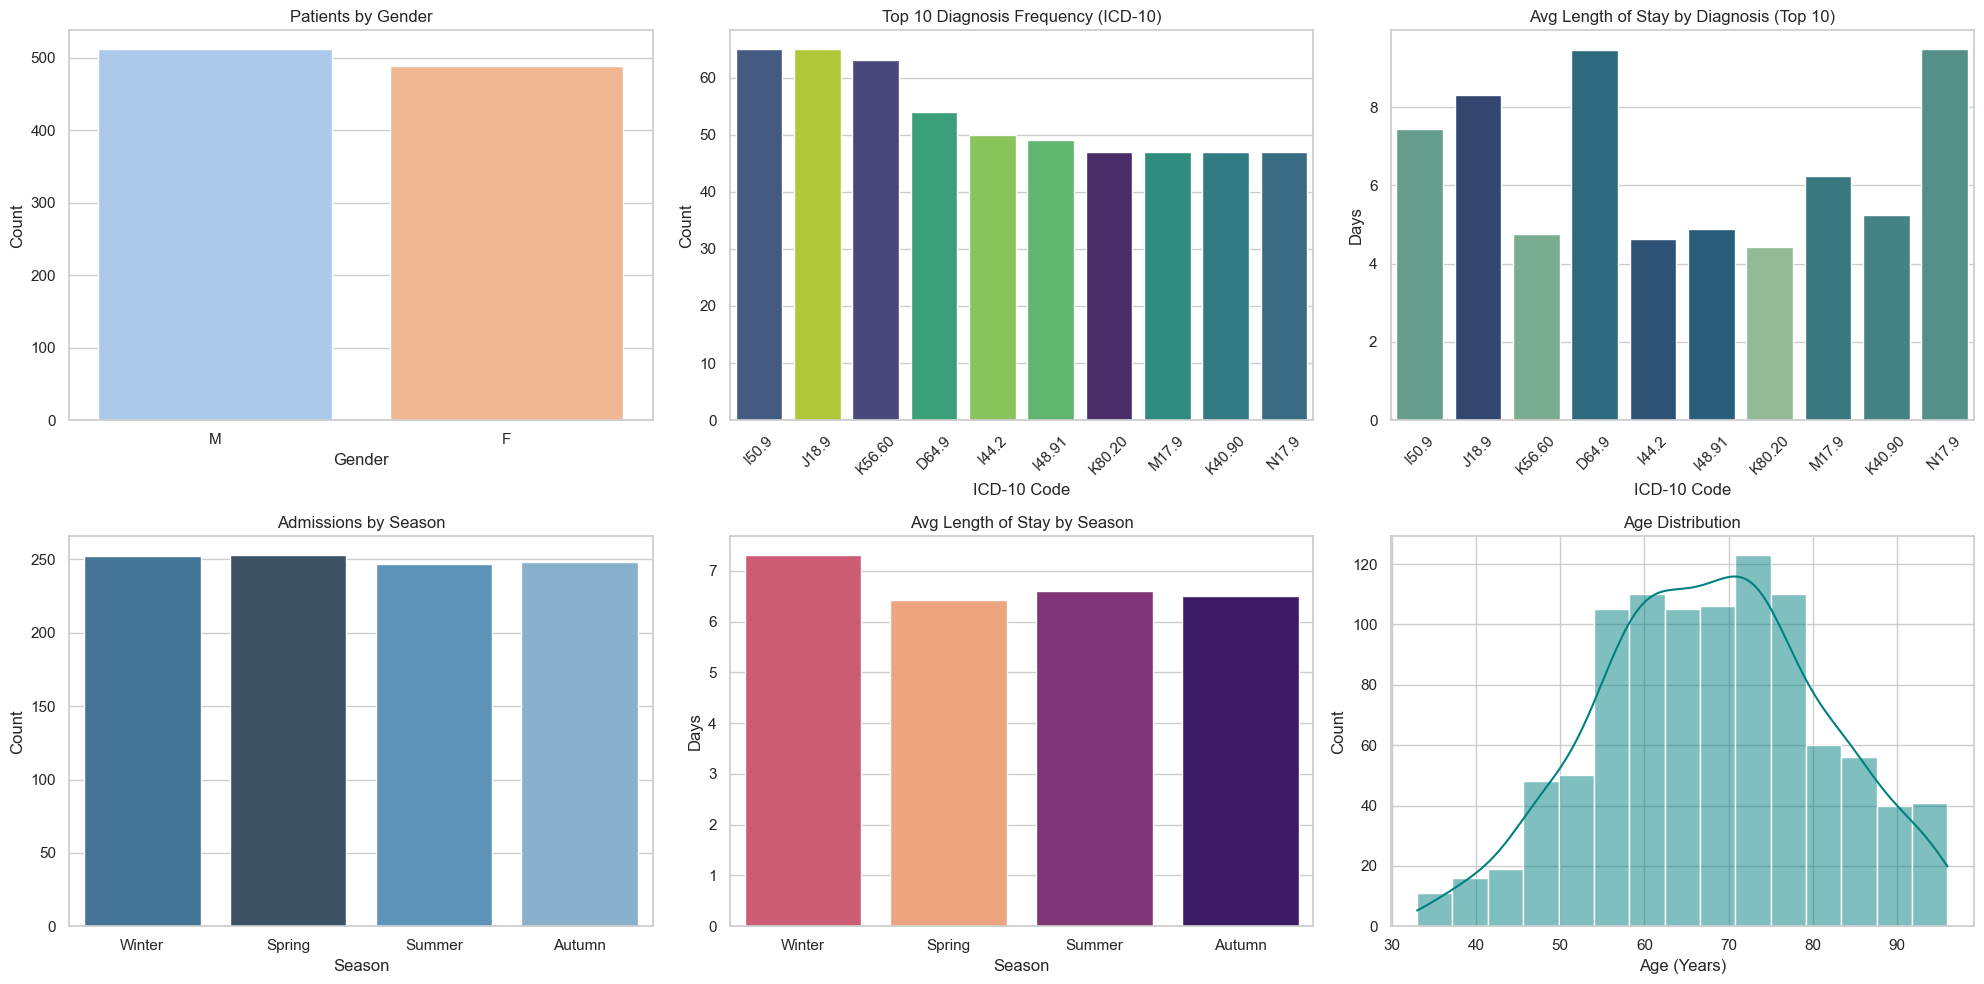

In [36]:
if df is not None:
    fig, axes = plt.subplots(2, 3, figsize=(20, 10))

    # Definir o Top 10 diagnósticos mais frequentes
    top_10_diag = df['diagnosis code'].value_counts().head(10).index
    df_top10 = df[df['diagnosis code'].isin(top_10_diag)]

    # 1. Gender Distribution (Linha 0, Coluna 0)
    sns.countplot(data=df, x='gender', hue='gender', palette='pastel', legend=False, ax=axes[0, 0])
    axes[0, 0].set_title('Patients by Gender')
    axes[0, 0].set_xlabel('Gender')
    axes[0, 0].set_ylabel('Count')

    # 2. Top 10 Diagnosis Frequency (Linha 0, Coluna 1)
    sns.countplot(
        data=df_top10, 
        x='diagnosis code', 
        hue='diagnosis code',
        palette='viridis', 
        order=top_10_diag, 
        legend=False,
        ax=axes[0, 1]
    )
    axes[0, 1].set_title('Top 10 Diagnosis Frequency (ICD-10)')
    axes[0, 1].set_xlabel('ICD-10 Code')
    axes[0, 1].set_ylabel('Count')
    axes[0, 1].tick_params(axis='x', rotation=45)

    # 3. Average Length of Stay by Diagnosis Code (Linha 0, Coluna 2)
    sns.barplot(
        data=df_top10, 
        x='diagnosis code', 
        y='los_days', 
        hue='diagnosis code',
        palette='crest', 
        order=top_10_diag,
        errorbar=None, 
        legend=False,
        ax=axes[0, 2]
    )
    axes[0, 2].set_title('Avg Length of Stay by Diagnosis (Top 10)')
    axes[0, 2].set_xlabel('ICD-10 Code')
    axes[0, 2].set_ylabel('Days')
    axes[0, 2].tick_params(axis='x', rotation=45)

    # 4. Admissions by Season (Linha 1, Coluna 0)
    sns.countplot(
        data=df, 
        x='season', 
        hue='season', 
        palette='Blues_d', 
        order=['Winter', 'Spring', 'Summer', 'Autumn'],
        legend=False, 
        ax=axes[1, 0]
    )
    axes[1, 0].set_title('Admissions by Season')
    axes[1, 0].set_xlabel('Season')
    axes[1, 0].set_ylabel('Count')

    # 5. Average Length of Stay by Season (Linha 1, Coluna 1)
    sns.barplot(
        data=df, 
        x='season', 
        y='los_days', 
        hue='season', 
        palette='magma', 
        order=['Winter', 'Spring', 'Summer', 'Autumn'],
        errorbar=None, 
        legend=False, 
        ax=axes[1, 1]
    )
    axes[1, 1].set_title('Avg Length of Stay by Season')
    axes[1, 1].set_xlabel('Season')
    axes[1, 1].set_ylabel('Days')

    # 6. Age Distribution (Linha 1, Coluna 2)
    sns.histplot(data=df, x='age', kde=True, color='teal', bins=15, ax=axes[1, 2])
    axes[1, 2].set_title('Age Distribution')
    axes[1, 2].set_xlabel('Age (Years)')
    axes[1, 2].set_ylabel('Count')

    plt.tight_layout()
    plt.show()